# Analisis Topic Modelling (LDA)
**Konstruk:** Digital Servitization · Ethical Leadership · Dynamic Capabilities

Prosedur yang dilakukan:

1. Pembersihan teks: boilerplate penerbit, sitasi, daftar pustaka, perbaikan ligatur PDF (fi/fl/ff), sambungan kata terpotong.
2. Stopword bahasa Inggris + stopword akademik, normalisasi bentuk jamak, deteksi frasa (bigram → satu token, mis. `digital_servitization`).
3. Pemilihan jumlah topik *k* = 2–10 dengan koherensi **C_v** dan **UMass** (3 seed per *k*).
4. Model final dipilih dari 10 restart berdasarkan log-likelihood; uji robustness antar-seed.
5. Visualisasi gaya pyLDAvis (intertopic distance map + top-30 term relevan, λ = 0,6).
6. Bigram **per topik** (difilter NPMI), tabulasi silang topik × kata kunci asal, dokumen representatif, dan sensitivitas *k* = 4.

## 1. Memuat dan membersihkan data

Dataset yang dipakai adalah 240 artikel (pypdf + normalisasi Unicode NFKC), sehingga:
- **tidak ada teks yang terpotong**. karena satu sel excel hanya memuat 32.767 karakter
- **ligatur fi/fl/ff sudah utuh**, perbaikan ligatur

Karena teks lengkap juga memuat **daftar pustaka**, bagian itu dipotong. Aturannya: judul *References/Bibliography* di 60% akhir teks yang diikuti entri bernomor atau pola "Nama, I.". Bila pola itu tidak ditemukan, dipakai judul polos di 40% akhir teks. Daftar pustaka harus dibuang agar nama penulis yang disitasi tidak membentuk topik. Sitasi dalam teks juga dihapus.

Normalisasi memakai pelipatan bentuk jamak yang dipandu korpus (`capabilities → capability`, `firms → firm`). Bentuk tunggal hanya dipakai bila muncul ≥ 5 kali di korpus.

In [97]:
   %pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [98]:
import sys
print(sys.executable)
print(sys.version)

C:\Program Files\Python312\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [99]:
%pip install numpy pandas scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
import os, glob
print("Folder kerja:", os.getcwd())
print("Isi folder:", os.listdir())
print("Folder data ada?", os.path.isdir("data"))
print("Cari file pkl/csv:", glob.glob("**/journal_fulltext.*", recursive=True))

Folder kerja: C:\LDA_SBMI
Isi folder: ['.ipynb_checkpoints', 'data', 'LDA_reanalysis_Jupiter.ipynb', 'Membuat_Dataset_Teks_FINAL.ipynb', 'output2']
Folder data ada? True
Cari file pkl/csv: ['data\\journal_fulltext.csv']


In [101]:
# ---- load + clean ----
import re, json, math, collections, itertools, warnings
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
warnings.filterwarnings("ignore")

DATA_FILE = Path(r"C:\Users\marfu\Documents\LDA_SBMI\data\journal_fulltext.csv")   # full-text dataset built with pypdf (Membuat_Dataset_Teks_Lengkap.ipynb)
df = pd.read_csv(DATA)
df["textdata"] = df["textdata"].astype(str)
GROUP = {"s": "Digital servitization", "e": "Ethical leadership", "d": "Dynamic capabilities"}
df["keyword"] = df["articlename"].str.extract(r"file\d+(\w)\.pdf")[0].map(GROUP)
df["n_char"] = df["textdata"].str.len()
print("Dokumen:", len(df))
print(df["keyword"].value_counts().to_string())
print(f"Rata-rata kata per artikel (teks lengkap): {df.textdata.str.split().str.len().mean():,.0f}; total {df.textdata.str.split().str.len().sum():,}")

BOILER = [
    r"contents lists available at sciencedirect", r"journal homepage:?\s*\S+",
    r"full terms (&|and)? ?conditions of access and use can be found at \S+",
    r"download(ed)? by:?.{0,80}?(date|at):?\s*[\d: ,a-z]{0,40}",
    r"©\s*\d{4}[^.]*\.", r"copyright[^.]*\.", r"all rights reserved\.?",
    r"https?:\S+", r"www\.\S+", r"\S+@\S+", r"doi:?\s*\S+", r"issn:?\s*[\dx\- ()a-z]{0,40}",
    r"a r t i c l e\s+i n f o", r"a b s t r a c t",
]
# reference-list heading followed by a numbered entry or an "Surname, I." author pattern
REF_HEAD = re.compile(r"\b(?:References|REFERENCES|Bibliography|BIBLIOGRAPHY|Reference list|Reference List|Literature Cited|Works cited)\b\s*:?\s*"
                      r"(?=\[1\]|1\.\s|.{0,15}?[A-Z\u00C0-\u00DE][\w\u00C0-\u017F'\- ]{1,30},\s?[A-Z\u00C0-\u00DE]\.)")

REF_LOOSE = re.compile(r"\b(?:References|REFERENCES|Bibliography|BIBLIOGRAPHY|Reference list|Literature Cited)\b\s*:?\s*(?=[A-Z\u00C0-\u00DE\[])")

def strip_text(t):
    # cut reference list (heading followed by "Surname, I")
    # first reference-list heading in the last 60% of the text
    m = next((x for x in REF_HEAD.finditer(t) if x.start() > 0.4 * len(t)), None)
    if m is None:   # fallback: a bare heading in the last 40% of the text
        m = next((x for x in REF_LOOSE.finditer(t) if x.start() > 0.6 * len(t)), None)
    if m:
        t = t[: m.start()]
    # narrative citations: Teece (2007), Teece et al. (2007), Teece and Pisano (1994)
    t = re.sub(r"\b[A-Z][A-Za-z\-']+(?:\s+et\s+al\.?|\s+(?:and|&)\s+[A-Z][A-Za-z\-']+)?,?\s*\((?:19|20)\d{2}[a-z]?\)", " ", t)
    # in-text citations: (Author, 2019; Author et al., 2020a)
    t = re.sub(r"\([^()]{0,200}?\b(19|20)\d{2}[a-z]?[^()]{0,200}?\)", " ", t)
    t = t.lower()
    for p in BOILER:
        t = re.sub(p, " ", t)
    return t

df["clean"] = df["textdata"].map(strip_text)

def ref_cut_share(t):
    m = next((x for x in REF_HEAD.finditer(t) if x.start() > 0.4 * len(t)), None)
    if m is None:
        m = next((x for x in REF_LOOSE.finditer(t) if x.start() > 0.6 * len(t)), None)
    return m.start() / len(t) if m else 1.0
df["kept_share"] = df["textdata"].map(ref_cut_share)
print(f"Daftar pustaka terdeteksi dan dipotong pada {(df.kept_share < 1).sum()} dari {len(df)} dokumen; "
      f"rata-rata {df.kept_share.mean():.1%} teks dipertahankan")

TOKEN = re.compile(r"[a-z]+")
raw_tokens = [TOKEN.findall(t) for t in df["clean"]]

Dokumen: 240
keyword
Digital servitization    80
Ethical leadership       80
Dynamic capabilities     80
Rata-rata kata per artikel (teks lengkap): 12,331; total 2,959,474
Daftar pustaka terdeteksi dan dipotong pada 231 dari 240 dokumen; rata-rata 77.2% teks dipertahankan


In [102]:
# ---- ligature repair (fi, fl, ff, ffi, ffl dropped by PDF extraction) ----
LIG_MARKERS = {"dierent", "benet", "benets", "signicant", "specic", "eect", "eects", "rms", "rm", "dened", "eld"}
df["lig_loss"] = [len(LIG_MARKERS & set(toks)) >= 2 for toks in raw_tokens]
print(f"Dokumen dengan ligatur hilang (fi/fl/ff): {df.lig_loss.sum()}")

clean_vocab = collections.Counter(w for toks, bad in zip(raw_tokens, df.lig_loss) if not bad for w in toks)
LIGS = ["ffi", "ffl", "fi", "fl", "ff"]
_repair_cache = {}
def repair(w):
    if w in _repair_cache:
        return _repair_cache[w]
    out = w
    if clean_vocab[w] < 3:
        best, bestf = None, 0
        for i in range(len(w) + 1):
            for L in LIGS:
                c = w[:i] + L + w[i:]
                f = clean_vocab.get(c, 0)
                if f > bestf:
                    best, bestf = c, f
        if best and bestf >= 5:
            out = best
    _repair_cache[w] = out
    return out

# hyphenation splits ("in dustrial", "stu dies"): join when the join is a known word and a part is not
def join_splits(toks):
    out, i = [], 0
    while i < len(toks):
        if i + 1 < len(toks):
            a, b = toks[i], toks[i + 1]
            j = a + b
            fa, fb, fj = clean_vocab.get(a, 0), clean_vocab.get(b, 0), clean_vocab.get(j, 0)
            if fj >= 10 and len(j) > 5 and (fa < 20 or fb < 20 or (fa < fj and fb < fj)):
                out.append(j); i += 2; continue
        out.append(toks[i]); i += 1
    return out

fixed = []
n_rep = 0
for toks, bad in zip(raw_tokens, df.lig_loss):
    if bad:
        new = [repair(w) for w in toks]
        n_rep += sum(a != b for a, b in zip(toks, new))
        toks = new
    fixed.append(join_splits(toks))
print(f"Token yang diperbaiki (ligatur): {n_rep:,}")
print("Contoh perbaikan:", {k: v for k, v in list(_repair_cache.items()) if k != v and k in LIG_MARKERS})

Dokumen dengan ligatur hilang (fi/fl/ff): 0
Token yang diperbaiki (ligatur): 0
Contoh perbaikan: {}


In [103]:
# ---- stopwords: sklearn English list + academic boilerplate ----
ACADEMIC = """al et ie eg vol pp journal article paper study studies research researchers author authors table figure fig
section results result findings finding analysis data sample method methods methodology approach
hypothesis hypotheses literature review university department school faculty email address correspondence corresponding
xx xxx xxxx xxxxx xxxxxx abstract introduction conclusion conclusions
keywords keyword published publisher press elsevier springer wiley emerald taylor francis sage ltd inc
received accepted revised available online use used using based also however thus therefore may can could
would might one two three first second third new will within among across well per et via i ii iii iv
significant significantly effect effects positive negative positively negatively level levels high higher low lower
mean sd std test tests variable variables measure measures measured scale item items construct constructs
respondents survey questionnaire regression correlation coefficient sem pls cfa ave cr vif
case cases example examples propose proposed show shows shown find found suggest suggests indicate indicates
provide provides important role impact relationship relationships factor factors aspect aspects type types
way ways number different specific various particular level context contexts terms term
""".split()
STOP = set(ENGLISH_STOP_WORDS) | set(ACADEMIC)

In [104]:
# ---- normalisation----
corpus_counts = collections.Counter(w for toks in fixed for w in toks)
def norm(w):
    for suf, rep in (("ies", "y"), ("sses", "ss"), ("es", ""), ("s", "")):
        if w.endswith(suf) and len(w) > len(suf) + 2:
            c = w[: -len(suf)] + rep
            if corpus_counts.get(c, 0) >= 5 and not w.endswith("ss") and not w.endswith("us") and not w.endswith("is"):
                return c
    return w
NORM = {}
def tok_ok(w):
    return len(w) > 2 and w not in STOP

# sequence with stopwords removed but adjacency broken at removed words (None = break)
seqs = []
for toks in fixed:
    s = []
    for w in toks:
        w2 = NORM.setdefault(w, norm(w))
        s.append(w2 if tok_ok(w2) and tok_ok(w) else None)
    seqs.append(s)
print("Contoh normalisasi:", {k: NORM[k] for k in ["capabilities", "firms", "services", "leaders", "employees", "technologies", "strategies"] if k in NORM})

Contoh normalisasi: {'capabilities': 'capability', 'firms': 'firm', 'services': 'service', 'leaders': 'leader', 'employees': 'employee', 'technologies': 'technology', 'strategies': 'strategy'}


## 2. Deteksi frasa dan matriks dokumen–term

Bigram yang sering muncul bersama (n ≥ 20, NPMI ≥ 0,35) digabung menjadi satu token, setara `gensim.models.Phrases` dengan skor NPMI. Pasangan kata hanya dihitung bila **bersebelahan di teks asli** — stopword di antaranya memutus pasangan, sehingga tidak muncul pasangan semu seperti *"relationship ethical"* atau *"leadership positively"*. Nama jurnal yang bocor dari header halaman diblokir.

Term yang muncul di < 5 dokumen atau > 90 % dokumen dibuang.

In [105]:
# ---- phrase detection (like gensim Phrases, NPMI scoring) + document-term matrix ----
from sklearn.feature_extraction.text import CountVectorizer

uni = collections.Counter(w for s in seqs for w in s if w)
bi = collections.Counter((a, b) for s in seqs for a, b in zip(s, s[1:]) if a and b)
N_TOK = sum(uni.values())
PHRASE_MIN, PHRASE_NPMI = 20, 0.35

def npmi_score(a, b, n_ab):
    p_ab = n_ab / N_TOK
    return math.log(p_ab / ((uni[a] / N_TOK) * (uni[b] / N_TOK))) / -math.log(p_ab)

# journal names that leak in from running headers are not concepts
PHRASE_BLOCK = {("industrial", "marketing"), ("marketing", "management"), ("strategic", "management"), ("technological", "forecasting"),
                ("forecasting", "social"), ("cleaner", "production"), ("production", "economics"),
                ("creative", "common"), ("open", "access"), ("publishing", "limited")}
PHRASES = {(a, b) for (a, b), n in bi.items()
           if n >= PHRASE_MIN and npmi_score(a, b, n) >= PHRASE_NPMI and (a, b) not in PHRASE_BLOCK}
print(f"Frasa (bigram) yang digabung jadi satu token: {len(PHRASES)}")
check = [("digital", "servitization"), ("dynamic", "capability"), ("ethical", "leadership"), ("business", "model"), ("competitive", "advantage")]
print("Frasa kunci:", {f"{a}_{b}": ((a, b) in PHRASES, bi[(a, b)]) for a, b in check})

def merge(s):
    out, i = [], 0
    while i < len(s):
        if s[i] and i + 1 < len(s) and s[i + 1] and (s[i], s[i + 1]) in PHRASES:
            out.append(s[i] + "_" + s[i + 1]); i += 2
        else:
            if s[i]:
                out.append(s[i])
            i += 1
    return out

docs = [merge(s) for s in seqs]
df["n_tokens"] = [len(d) for d in docs]

MIN_DF, MAX_DF = 5, 0.90
vec = CountVectorizer(analyzer=lambda x: x, min_df=MIN_DF, max_df=MAX_DF)
X = vec.fit_transform(docs)
vocab = np.array(vec.get_feature_names_out())
print(f"Matriks dokumen-term: {X.shape[0]} dokumen x {X.shape[1]:,} term, {int(X.sum()):,} token")
doc_freq = collections.Counter(w for d in docs for w in set(d))
print("Term dibuang karena muncul di >90% dokumen:", sorted(w for w, c in doc_freq.items() if c > MAX_DF * len(docs)))

Frasa (bigram) yang digabung jadi satu token: 862
Frasa kunci: {'digital_servitization': (True, 4546), 'dynamic_capability': (True, 5369), 'ethical_leadership': (True, 6596), 'business_model': (True, 2626), 'competitive_advantage': (True, 953)}
Matriks dokumen-term: 240 dokumen x 7,391 term, 817,464 token
Term dibuang karena muncul di >90% dokumen: ['business', 'create', 'develop', 'development', 'discussion', 'environment', 'focus', 'following', 'future', 'help', 'include', 'information', 'knowledge', 'make', 'management', 'model', 'need', 'opportunity', 'performance', 'perspective', 'potential', 'practice', 'process', 'related', 'set', 'support', 'time', 'value', 'work']


## 3. Memilih jumlah topik (*k*)

LDA dijalankan untuk *k* = 2–10, masing-masing dengan 3 random seed. Prior simetris α = η = 1/*k* (default gensim dan scikit-learn), `learning_method="batch"`, 150 iterasi.

- **C_v** (Röder et al., 2015): jendela geser boolean 110 token, NPMI, segmentasi *one-set*, kemiripan kosinus tidak langsung. Lebih tinggi = lebih baik.
- **UMass** (Mimno et al., 2011): ko-okurensi tingkat dokumen. Mendekati 0 = lebih baik.

In [106]:
# ----LDA for k = 2..10, several seeds; coherence C_v and UMass ----
from sklearn.decomposition import LatentDirichletAllocation
from scipy import sparse

K_RANGE = range(2, 11)
SEEDS = [11, 23, 42]
TOPN = 10
LDA_KW = dict(learning_method="batch", max_iter=150, evaluate_every=-1, n_jobs=-1)  # alpha = eta = 1/k (symmetric, default)

def fit_lda(k, seed):
    m = LatentDirichletAllocation(n_components=k, random_state=seed, **LDA_KW)
    theta = m.fit_transform(X)
    phi = m.components_ / m.components_.sum(1, keepdims=True)
    return m, theta, phi

def top_words(phi, n=TOPN):
    return [list(vocab[np.argsort(-row)[:n]]) for row in phi]

# --- reference statistics for coherence: boolean sliding window (110 tokens) for C_v, document co-occurrence for UMass
WIN = 110
w2i = {w: i for i, w in enumerate(vocab)}
def window_cooc(words):
    idx = {w: j for j, w in enumerate(words)}
    C = np.zeros((len(words), len(words)))
    n_win = 0
    for d in docs:
        pos = np.array([idx.get(w, -1) for w in d])
        L = len(d)
        if L == 0:
            continue
        n_w = max(1, L - WIN + 1)
        M = np.zeros((n_w, len(words)), dtype=np.float32)
        ind = np.zeros((L, len(words)), dtype=np.float32)
        ok = pos >= 0
        ind[np.where(ok)[0], pos[ok]] = 1
        cs = np.vstack([np.zeros((1, len(words)), np.float32), np.cumsum(ind, 0)])
        if L >= WIN:
            M = (cs[WIN:] - cs[:-WIN]) > 0
        else:
            M = (cs[-1:] > 0)
        M = M.astype(np.float32)
        C += M.T @ M
        n_win += M.shape[0]
    return C, n_win

Xb = (X > 0).astype(np.float32)
def coherence_cv(topics, C, n_win, idx):
    eps = 1e-12
    scores = []
    for T in topics:
        ii = [idx[w] for w in T]
        P = C[np.ix_(ii, ii)] / n_win
        p = np.diag(P)
        with np.errstate(divide="ignore", invalid="ignore"):
            pmi = np.log((P + eps) / np.outer(p, p))
            npmi = pmi / -np.log(P + eps)
        np.fill_diagonal(npmi, 1.0)
        vW = npmi.sum(0)
        cos = (npmi @ vW) / (np.linalg.norm(npmi, axis=1) * np.linalg.norm(vW))
        scores.append(float(np.mean(cos)))
    return scores

def coherence_umass(topics):
    out = []
    for T in topics:
        cols = [w2i[w] for w in T]
        B = Xb[:, cols].toarray()
        D = B.T @ B
        s = [math.log((D[i, j] + 1) / D[j, j]) for i in range(1, len(T)) for j in range(i)]
        out.append(float(np.mean(s)))
    return out

grid = []
models = {}
for k in K_RANGE:
    for seed in SEEDS:
        m, theta, phi = fit_lda(k, seed)
        models[(k, seed)] = (m, theta, phi)
        grid.append(dict(k=k, seed=seed, perplexity=m.perplexity(X), topics=top_words(phi)))

all_words = sorted({w for g in grid for T in g["topics"] for w in T})
C_win, N_WIN = window_cooc(all_words)
idx_all = {w: i for i, w in enumerate(all_words)}
for g in grid:
    g["c_v"] = float(np.mean(coherence_cv(g["topics"], C_win, N_WIN, idx_all)))
    g["u_mass"] = float(np.mean(coherence_umass(g["topics"])))
grid_df = pd.DataFrame(grid).drop(columns="topics")
coh = grid_df.groupby("k").agg(c_v_mean=("c_v", "mean"), c_v_sd=("c_v", "std"),
                               u_mass_mean=("u_mass", "mean"), u_mass_sd=("u_mass", "std"),
                               perplexity=("perplexity", "mean")).round(4)
print(coh.to_string())

    c_v_mean  c_v_sd  u_mass_mean  u_mass_sd  perplexity
k                                                       
2     0.6868  0.0000      -0.2244     0.0000   1913.5164
3     0.7132  0.0000      -0.2084     0.0006   1803.3571
4     0.6824  0.0177      -0.3163     0.0059   1768.2960
5     0.6792  0.0309      -0.3438     0.0479   1744.7921
6     0.6238  0.0378      -0.4563     0.0808   1727.8519
7     0.6463  0.0478      -0.4205     0.0963   1714.7377
8     0.6570  0.0330      -0.4382     0.1024   1703.2673
9     0.6502  0.0522      -0.4592     0.0248   1694.4557
10    0.6395  0.0418      -0.3924     0.0382   1684.8988


## 4. Model final (*k* = 3), robustness, dan tabel hasil

LDA bisa konvergen ke solusi berbeda tergantung seed. Karena itu model dijalankan 10 kali dan dipilih yang log-likelihood-nya tertinggi. Kesamaan tiap restart dengan model final diukur dengan ARI (penugasan topik dominan), Jaccard top-10 term, dan jarak Jensen–Shannon.

**Notasi.** Bobot term dilaporkan sebagai **φ = p(w | t)**. Huruf **λ** hanya dipakai untuk parameter *relevance* pyLDAvis.

In [107]:
# ---- final model (k = 3), selected among 10 restarts by log-likelihood ----
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import jensenshannon
import matplotlib

import matplotlib.pyplot as plt

K = 3
FINAL_SEEDS = list(range(1, 11))
runs = []
for s in FINAL_SEEDS:
    m, theta, phi = fit_lda(K, s)
    runs.append(dict(seed=s, model=m, theta=theta, phi=phi, loglik=m.score(X), topics=top_words(phi)))
best = max(runs, key=lambda r: r["loglik"])
lda, theta, phi = best["model"], best["theta"], best["phi"]
print(f"Model final: k = {K}, seed = {best['seed']} (log-likelihood tertinggi dari {len(runs)} restart)")
print(f"Prior: alpha = {lda.doc_topic_prior_:.4f}, eta = {lda.topic_word_prior_:.4f}; iterasi = {lda.n_iter_}; perplexity = {lda.perplexity(X):.1f}")

# order topics: servitization, ethical leadership, dynamic capabilities (by which keyword group dominates each topic)
dom = theta.argmax(1)
ct = pd.crosstab(df["keyword"], dom)
order_kw = ["Digital servitization", "Ethical leadership", "Dynamic capabilities"]
perm = [int(ct.loc[kw].idxmax()) for kw in order_kw]
if len(set(perm)) < K:
    perm = list(range(K))
theta, phi = theta[:, perm], phi[perm]
dom = theta.argmax(1)
df["dominant_topic"] = dom + 1
df["dominant_weight"] = theta.max(1).round(3)

Model final: k = 3, seed = 3 (log-likelihood tertinggi dari 10 restart)
Prior: alpha = 0.3333, eta = 0.3333; iterasi = 150; perplexity = 1803.3


In [108]:
# ---- robustness: compare every restart with the final model ----
rob = []
for r in runs:
    D = np.array([[jensenshannon(a, b) for b in r["phi"]] for a in phi])
    ri, ci = linear_sum_assignment(D)
    th = r["theta"][:, ci]
    jac = [len(set(top_words(phi)[i]) & set(r["topics"][j])) / len(set(top_words(phi)[i]) | set(r["topics"][j])) for i, j in zip(ri, ci)]
    rob.append(dict(seed=r["seed"], log_likelihood=round(r["loglik"], 1),
                    ARI_vs_final=round(adjusted_rand_score(dom, th.argmax(1)), 3),
                    mean_top10_jaccard=round(float(np.mean(jac)), 3),
                    mean_JS_distance=round(float(D[ri, ci].mean()), 3)))
rob_df = pd.DataFrame(rob).sort_values("log_likelihood", ascending=False)
print(rob_df.to_string(index=False))

 seed  log_likelihood  ARI_vs_final  mean_top10_jaccard  mean_JS_distance
    3      -6128848.1           1.0                 1.0             0.000
    8      -6128848.4           1.0                 1.0             0.002
   10      -6128848.4           1.0                 1.0             0.002
    6      -6128848.9           1.0                 1.0             0.003
    4      -6128849.0           1.0                 1.0             0.003
    9      -6128849.3           1.0                 1.0             0.002
    1      -6128850.1           1.0                 1.0             0.003
    2      -6128862.5           1.0                 1.0             0.007
    5      -6128862.6           1.0                 1.0             0.007
    7      -6128863.4           1.0                 1.0             0.008


In [109]:
# ---- pyLDAvis quantities (Sievert & Shirley 2014) ----
doc_len = np.asarray(X.sum(1)).ravel()
term_freq = np.asarray(X.sum(0)).ravel()
p_w = term_freq / term_freq.sum()
topic_tokens = (theta * doc_len[:, None]).sum(0)
topic_share = topic_tokens / topic_tokens.sum()
term_topic_freq = phi * topic_tokens[:, None]
term_topic_freq = term_topic_freq * (term_freq / term_topic_freq.sum(0))  # rescale to observed totals, as pyLDAvis does

def relevance(t, lam):
    return lam * np.log(phi[t]) + (1 - lam) * np.log(phi[t] / p_w)

# inter-topic map: Jensen-Shannon distance + classical MDS (PCoA), pyLDAvis default
JS = np.array([[jensenshannon(a, b) ** 2 for b in phi] for a in phi])
n = K
J = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * J @ JS @ J
vals, vecs = np.linalg.eigh(B)
o = np.argsort(vals)[::-1][:2]
coords = vecs[:, o] * np.sqrt(np.maximum(vals[o], 0))

In [110]:
# ---- LABELS: assigned after reading top terms, bigrams and representative documents----
TOPIC_LABELS = ["Digital Servitization", "Ethical Leadership", "Dynamic Capabilities"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK2, MUTED, BG, GRID, OVERALL = "#0b0b0b", "#52514e", "#898781", "#fcfcfb", "#e6e5e0", "#d9d8d4"

summary = pd.DataFrame({
    "Topik": [f"Topic {i+1}: {TOPIC_LABELS[i]}" for i in range(K)],
    "Porsi token (%)": (topic_share * 100).round(1),
    "Dokumen dominan (n)": [int((dom == i).sum()) for i in range(K)],
    "C_v": np.round(coherence_cv(top_words(phi), *window_cooc(sorted({w for T in top_words(phi) for w in T}))[:2],
                                 {w: i for i, w in enumerate(sorted({w for T in top_words(phi) for w in T}))}), 3),
    "UMass": np.round(coherence_umass(top_words(phi)), 3),
})
print(summary.to_string(index=False))

                         Topik  Porsi token (%)  Dokumen dominan (n)   C_v  UMass
Topic 1: Digital Servitization             40.4                   86 0.745 -0.275
   Topic 2: Ethical Leadership             25.9                   76 0.829 -0.243
 Topic 3: Dynamic Capabilities             33.7                   78 0.565 -0.106


In [111]:
# ----top terms per topic (phi = p(w|t)) and by relevance lambda = 0.6 ----
rows = []
for t in range(K):
    by_phi = np.argsort(-phi[t])[:15]
    by_rel = np.argsort(-relevance(t, 0.6))[:15]
    for r in range(15):
        rows.append({"Topik": t + 1, "Label": TOPIC_LABELS[t], "Rank": r + 1,
                     "Term (phi)": vocab[by_phi[r]], "phi = p(w|t)": round(float(phi[t, by_phi[r]]), 4),
                     "Term (relevance, lambda=0.6)": vocab[by_rel[r]],
                     "phi term relevance": round(float(phi[t, by_rel[r]]), 4)})
top_terms = pd.DataFrame(rows)
wide = pd.concat([top_terms[top_terms.Topik == t + 1][["Term (phi)", "phi = p(w|t)"]].reset_index(drop=True)
                  .rename(columns={"Term (phi)": f"T{t+1} term", "phi = p(w|t)": f"T{t+1} phi"}) for t in range(K)], axis=1).head(10)
wide.index = wide.index + 1
print(wide.to_string())

                  T1 term  T1 phi             T2 term  T2 phi             T3 term  T3 phi
1                 service  0.0233  ethical_leadership  0.0307  dynamic_capability  0.0192
2                 digital  0.0150            employee  0.0285                firm  0.0180
3                customer  0.0145              leader  0.0178          capability  0.0159
4   digital_servitization  0.0137             ethical  0.0144          innovation  0.0103
5                 product  0.0106            behavior  0.0136            resource  0.0074
6                 company  0.0093          leadership  0.0109              market  0.0063
7           servitization  0.0092        organization  0.0096        organization  0.0063
8                    firm  0.0071          individual  0.0060      organizational  0.0054
9          business_model  0.0067      ethical_leader  0.0058          technology  0.0048
10               solution  0.0061      organizational  0.0057              change  0.0046


In [112]:
# ---- bigrams per topic
bg_rows = []
for t in range(K):
    sub = [seqs[i] for i in np.where(dom == t)[0]]
    u = collections.Counter(w for s in sub for w in s if w)
    b = collections.Counter((x, y) for s in sub for x, y in zip(s, s[1:]) if x and y and x != y)
    N = sum(u.values())
    cand = []
    for (x, y), c in b.items():
        if c < 10:
            continue
        pab = c / N
        npmi = math.log(pab / ((u[x] / N) * (u[y] / N))) / -math.log(pab)
        if npmi >= 0.25:
            cand.append((x + " " + y, c, round(npmi, 3)))
    cand.sort(key=lambda z: -z[1])
    for r, (bgm, c, s) in enumerate(cand[:15]):
        bg_rows.append({"Topik": t + 1, "Label": TOPIC_LABELS[t], "Rank": r + 1, "Bigram": bgm, "Frekuensi": c, "NPMI": s})
bigram_df = pd.DataFrame(bg_rows)
for t in range(K):
    print(f"T{t+1}:", ", ".join(f"{r.Bigram} ({r.Frekuensi})" for r in bigram_df[bigram_df.Topik == t + 1].head(10).itertuples()))

# corpus-wide bigrams
b_all = collections.Counter((x, y) for s in seqs for x, y in zip(s, s[1:]) if x and y and x != y)
corpus_bigrams = pd.DataFrame([(f"{x} {y}", c) for (x, y), c in b_all.most_common(15)], columns=["Bigram", "Frekuensi"])
corpus_bigrams.index = corpus_bigrams.index + 1

T1: digital servitization (4521), business model (1955), digital service (1255), digital technology (1229), digital transformation (539), value proposition (493), product service (490), digital platform (415), manufacturing firm (398), supply chain (397)
T2: ethical leadership (6355), ethical leader (1208), knowledge sharing (502), job satisfaction (462), ethical climate (377), work engagement (334), moral identity (328), decision making (308), psychological empowerment (298), work behavior (277)
T3: dynamic capability (5050), supply chain (1207), business model (668), competitive advantage (655), digital transformation (508), green innovation (362), decision making (302), ordinary capability (281), innovation performance (259), firm performance (249)


In [113]:
# ---- topic x keyword cross-tab ----
xtab = pd.crosstab(df["keyword"], df["dominant_topic"].map(lambda t: f"T{t} {TOPIC_LABELS[t-1]}"), margins=True, margins_name="Total")
xtab = xtab.reindex(order_kw + ["Total"])
mean_theta = pd.DataFrame(theta, columns=[f"T{t+1}" for t in range(K)]).groupby(df["keyword"].values).mean().reindex(order_kw).round(3)
print(xtab.to_string()); print(mean_theta.to_string())

dominant_topic         T1 Digital Servitization  T2 Ethical Leadership  T3 Dynamic Capabilities  Total
keyword                                                                                               
Digital servitization                        80                      0                        0     80
Ethical leadership                            0                     76                        4     80
Dynamic capabilities                          6                      0                       74     80
Total                                        86                     76                       78    240
                          T1     T2     T3
Digital servitization  0.910  0.008  0.082
Ethical leadership     0.017  0.911  0.072
Dynamic capabilities   0.134  0.024  0.842


In [114]:
# ---- representative documents per topic (for close reading) ----
def snippet(t, n=160):
    t = re.sub(r"\s+", " ", t).strip()
    return t[:n]
rep = []
for t in range(K):
    for i in np.argsort(-theta[:, t])[:8]:
        rep.append({"Topik": t + 1, "Label": TOPIC_LABELS[t], "File": df.articlename[i], "Kata kunci asal": df.keyword[i],
                    "theta": round(float(theta[i, t]), 3), "Awal teks (untuk identifikasi)": snippet(df.textdata[i])})
rep_df = pd.DataFrame(rep)

In [115]:
# ---- inter-topic distance + shared vocabulary ----
top30 = [set(vocab[np.argsort(-relevance(t, 0.6))[:30]]) for t in range(K)]
pairs = []
for a, b in itertools.combinations(range(K), 2):
    pairs.append({"Pasangan": f"T{a+1}-T{b+1}", "JS distance": round(float(np.sqrt(JS[a, b])), 3),
                  "Term sama di top-30 (lambda=0.6)": ", ".join(sorted(top30[a] & top30[b])) or "-"})
pair_df = pd.DataFrame(pairs)
print(pair_df.to_string(index=False))

Pasangan  JS distance                 Term sama di top-30 (lambda=0.6)
   T1-T2        0.530                                                -
   T1-T3        0.387 capability, firm, industry, strategy, technology
   T2-T3        0.466                     organization, organizational


In [116]:
# ---- sensitivity: k = 4 (best of the grid seeds by log-likelihood) ----
k4 = max([(k, s) for (k, s) in models if k == 4], key=lambda ks: models[ks][0].score(X))
th4, ph4 = models[k4][1], models[k4][2]
k4_terms = pd.DataFrame({f"T{t+1}": list(vocab[np.argsort(-ph4[t])[:10]]) for t in range(4)})
k4_xtab = pd.crosstab(df["keyword"], th4.argmax(1) + 1).reindex(order_kw)
print(k4_terms.to_string()); print(k4_xtab.to_string())

                   T1                  T2                  T3                     T4
0                firm  dynamic_capability  ethical_leadership                service
1          capability                firm            employee                digital
2          innovation          capability              leader               customer
3  dynamic_capability        organization             ethical  digital_servitization
4        supply_chain              change            behavior                product
5            resource          innovation          leadership          servitization
6               green      organizational        organization                company
7              market              market      ethical_leader         business_model
8         integration          technology            follower               solution
9            industry           ecosystem               moral                   firm
col_0                   1   2   3   4
keyword                    

## 5. Visualisasi

Gambar gaya pyLDAvis dibuat dari besaran yang sama dengan pyLDAvis: porsi token per topik, peta antartopik (jarak Jensen–Shannon + MDS klasik/PCoA), serta relevance λ = 0,6. Abu-abu = frekuensi term di seluruh korpus; warna = estimasi frekuensi term di topik terpilih (tidak pernah melebihi abu-abu).

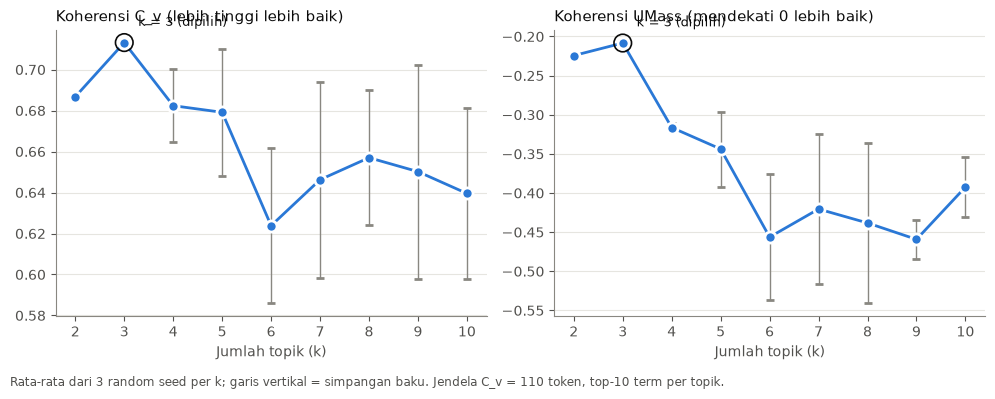

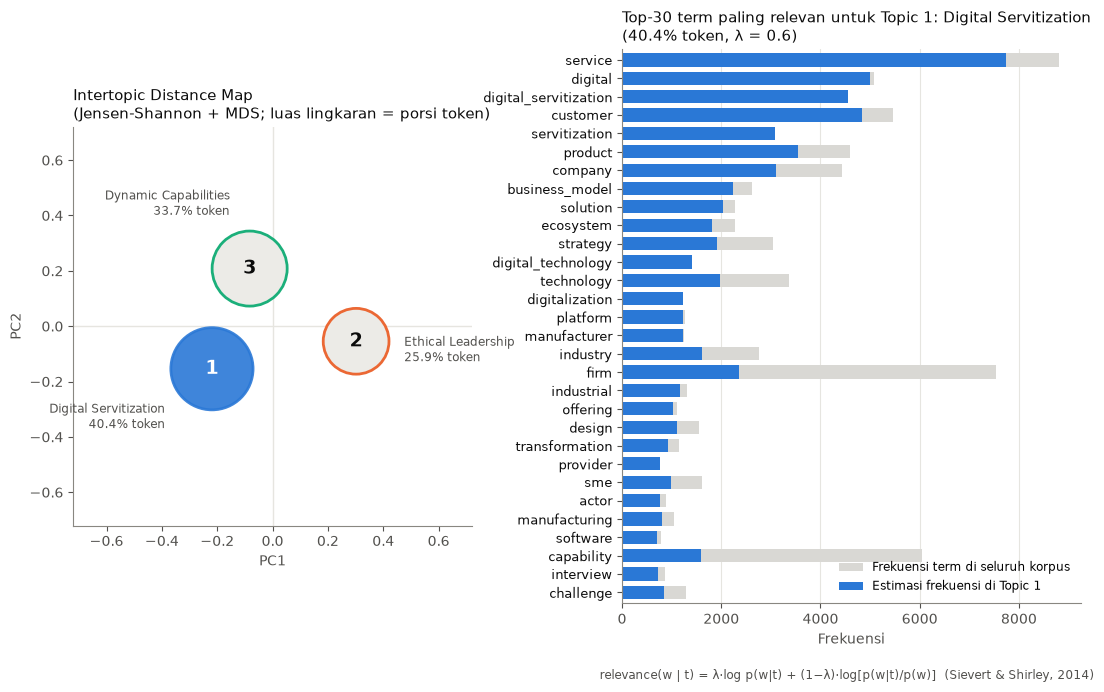

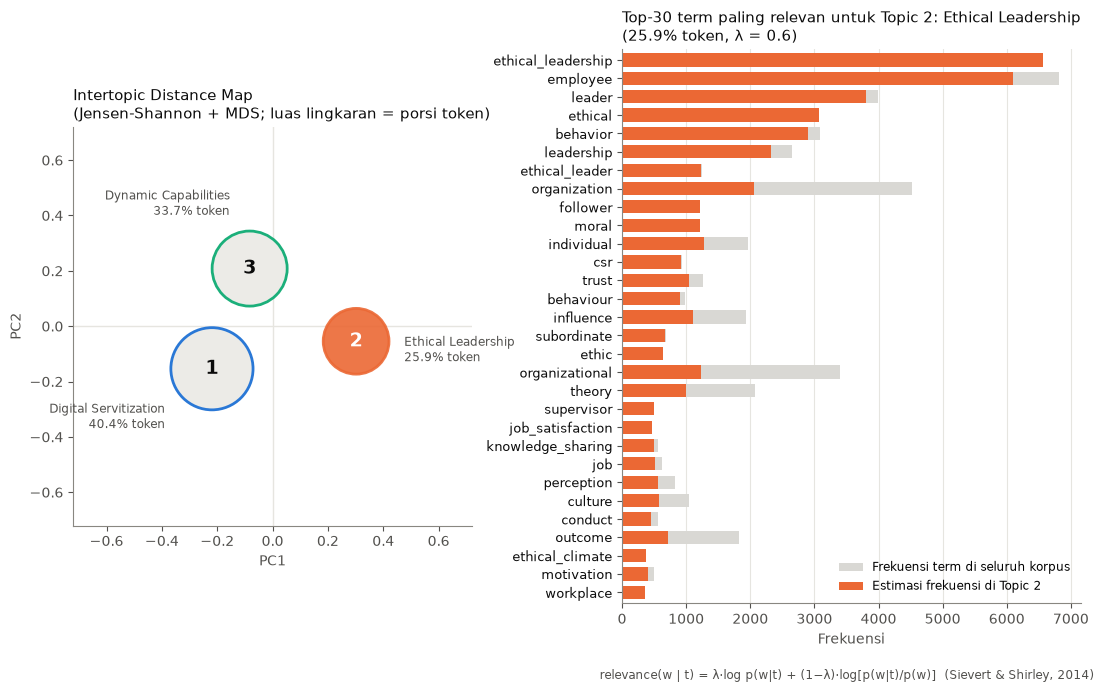

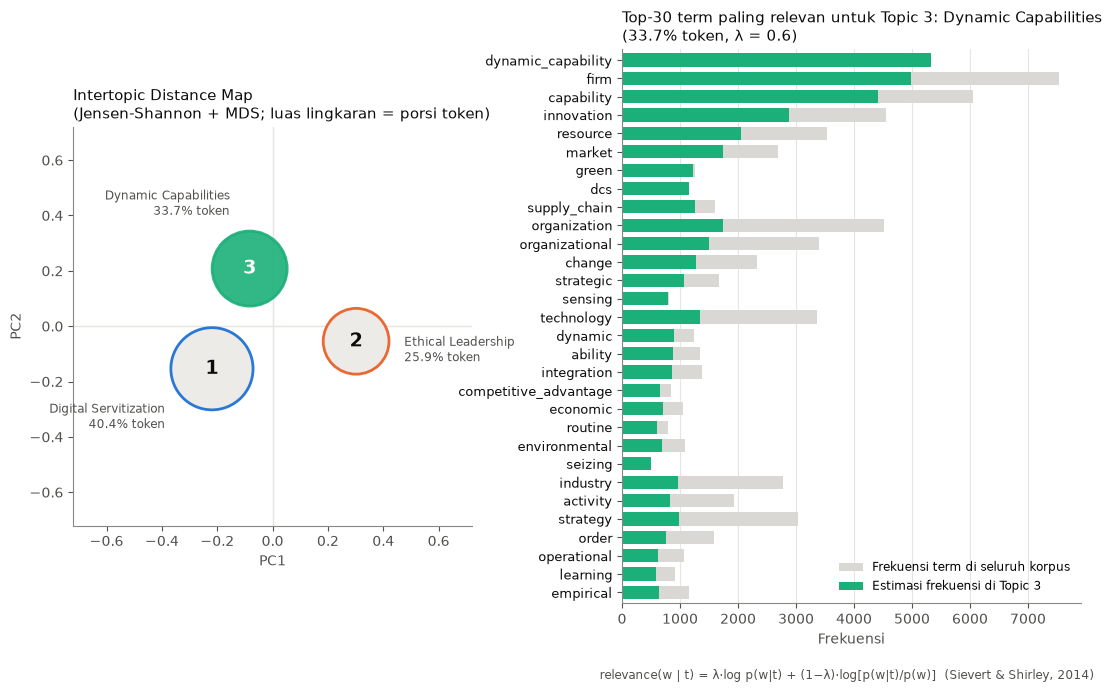

In [117]:
# ----figures ----
import os
os.makedirs("output2", exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 300})

# coherence by k (two panels, one measure each)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title, note in [(axes[0], "c_v", "Koherensi C_v (lebih tinggi lebih baik)", None),
                             (axes[1], "u_mass", "Koherensi UMass (mendekati 0 lebih baik)", None)]:
    g = grid_df.groupby("k")[col]
    mu, sd = g.mean(), g.std().fillna(0)
    ax.errorbar(mu.index, mu.values, yerr=sd.values, color=COLORS[0], lw=2, marker="o", ms=8,
                mec="white", mew=2, capsize=3, ecolor=MUTED, elinewidth=1)
    ax.scatter([K], [mu[K]], s=160, facecolors="none", edgecolors=INK, lw=1.2, zorder=5)
    ax.annotate(f"k = {K} (dipilih)", (K, mu[K]), xytext=(10, 12), textcoords="offset points", fontsize=9, color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Jumlah topik (k)")
    ax.set_xticks(list(K_RANGE))
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
fig.text(0.01, -0.03, f"Rata-rata dari {len(SEEDS)} random seed per k; garis vertikal = simpangan baku. Jendela C_v = {WIN} token, top-{TOPN} term per topik.",
         fontsize=8.5, color=INK2)
fig.tight_layout()
fig.savefig("output2/Gambar_koherensi_k.png", bbox_inches="tight")
plt.show()

# pyLDAvis-style panel per topic (intertopic map + top-30 relevant terms, lambda = 0.6)
LAMBDA = 0.6
def ldavis_panel(t):
    fig = plt.figure(figsize=(13, 7.2))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.35)
    ax = fig.add_subplot(gs[0])
    span = max(np.linalg.norm(coords[a] - coords[b]) for a in range(K) for b in range(a + 1, K))
    radii = np.sqrt(topic_share / topic_share.max()) * span * 0.28
    lim = (np.abs(coords).max() + radii.max()) * 1.6
    for i in range(K):
        r = radii[i]
        sel = i == t
        ax.add_patch(plt.Circle(coords[i], r, facecolor=COLORS[i] if sel else "#ecebe7", alpha=0.9 if sel else 1,
                                edgecolor=COLORS[i], lw=2))
        ax.text(*coords[i], f"{i+1}", ha="center", va="center", fontsize=14, weight="bold", color="white" if sel else INK)
        d = coords[i] / (np.linalg.norm(coords[i]) + 1e-12)
        lp = coords[i] + d * (r + lim * 0.08)
        ax.text(*lp, f"{TOPIC_LABELS[i]}\n{topic_share[i]*100:.1f}% token", ha="left" if d[0] > 0.3 else ("right" if d[0] < -0.3 else "center"),
                va="bottom" if d[1] > 0.3 else ("top" if d[1] < -0.3 else "center"), fontsize=8.5, color=INK2)
    ax.axhline(0, color=GRID, lw=1, zorder=0); ax.axvline(0, color=GRID, lw=1, zorder=0)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.set_title("Intertopic Distance Map\n(Jensen-Shannon + MDS; luas lingkaran = porsi token)", loc="left", fontsize=11, color=INK)

    ax2 = fig.add_subplot(gs[1])
    idx = np.argsort(-relevance(t, LAMBDA))[:30][::-1]
    y = np.arange(30)
    ax2.barh(y, term_freq[idx], color=OVERALL, height=0.72, label="Frekuensi term di seluruh korpus")
    ax2.barh(y, term_topic_freq[t, idx], color=COLORS[t], height=0.72, label=f"Estimasi frekuensi di Topic {t+1}")
    ax2.set_yticks(y); ax2.set_yticklabels(vocab[idx], fontsize=9, color=INK)
    ax2.set_ylim(-0.6, 29.6)
    ax2.grid(axis="x", color=GRID, lw=0.8); ax2.set_axisbelow(True)
    ax2.set_title(f"Top-30 term paling relevan untuk Topic {t+1}: {TOPIC_LABELS[t]}\n({topic_share[t]*100:.1f}% token, λ = {LAMBDA})",
                  loc="left", fontsize=11, color=INK)
    ax2.set_xlabel("Frekuensi")
    ax2.legend(loc="lower right", frameon=False, fontsize=8.5)
    fig.text(0.53, 0.005, "relevance(w | t) = λ·log p(w|t) + (1−λ)·log[p(w|t)/p(w)]  (Sievert & Shirley, 2014)", fontsize=8.5, color=INK2)
    fig.savefig(f"output2/Gambar_topic{t+1}_ldavis.png", bbox_inches="tight")
    plt.show()

for t in range(K):
    ldavis_panel(t)

In [118]:
# ---- Black-and-white figures
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from pathlib import Path
OUT_DIR = Path("output2")

BW_DIR = OUT_DIR / "figures_bw_en"
BW_DIR.mkdir(parents=True, exist_ok=True)
LABELS_EN = ["Digital Servitization", "Ethical Leadership", "Dynamic Capabilities"]
K_INK, K_INK2, K_MUTED, K_GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
BAR_ALL, BAR_TOPIC, CIRCLE_SEL = "#cfcfcf", "#2b2b2b", "#3a3a3a"

def save_gray(fig, path):
    fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=300)
    plt.close(fig)
    Image.open(path).convert("L").save(path, dpi=(300, 300))   # true grayscale PNG
    print("Saved:", path)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": K_MUTED, "axes.labelcolor": K_INK2,
                     "xtick.color": K_INK2, "ytick.color": K_INK2, "axes.spines.top": False, "axes.spines.right": False})

# Figure 2: coherence by k
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title in [(axes[0], "c_v", "C_v coherence (higher is better)"),
                       (axes[1], "u_mass", "UMass coherence (closer to 0 is better)")]:
    g = grid_df.groupby("k")[col]
    mu, sd = g.mean(), g.std().fillna(0)
    ax.errorbar(mu.index, mu.values, yerr=sd.values, color=K_INK, lw=2, marker="o", ms=8,
                mec="white", mew=2, capsize=3, ecolor=K_MUTED, elinewidth=1)
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.14 * (hi - lo))
    ax.scatter([K], [mu[K]], s=160, facecolors="none", edgecolors=K_INK, lw=1.2, zorder=5)
    ax.annotate(f"k = {K}", (K, mu[K]), xytext=(38, 10), textcoords="offset points", va="center", fontsize=9, color=K_INK,
                arrowprops=dict(arrowstyle="-", color="#555555", lw=0.8, shrinkA=2, shrinkB=7))
    ax.set_title(title, loc="left", fontsize=11, color=K_INK)
    ax.set_xlabel("Number of topics (k)"); ax.set_xticks(list(K_RANGE))
    ax.grid(axis="y", color=K_GRID, lw=0.8); ax.set_axisbelow(True)
fig.text(0.01, -0.03, f"Mean of {len(SEEDS)} random seeds per k; whiskers = ±1 SD. C_v sliding window = {WIN} tokens; top-{TOPN} terms per topic.",
         fontsize=8.5, color=K_INK2)
fig.tight_layout()
save_gray(fig, BW_DIR / "Fig2_coherence_bw.png")

# Figures 3-5: pyLDAvis-style panel per topic
def panel_bw(t, lam=0.6):
    fig = plt.figure(figsize=(13, 7.2))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.55)
    ax = fig.add_subplot(gs[0])
    span = max(np.linalg.norm(coords[a] - coords[b]) for a in range(K) for b in range(a + 1, K))
    radii = np.sqrt(topic_share / topic_share.max()) * span * 0.28
    lim = (np.abs(coords).max() + radii.max()) * 1.95
    for i in range(K):
        sel = i == t
        ax.add_patch(plt.Circle(coords[i], radii[i], facecolor=CIRCLE_SEL if sel else "white", edgecolor=K_INK, lw=2))
        ax.text(*coords[i], f"{i+1}", ha="center", va="center", fontsize=14, weight="bold", color="white" if sel else K_INK)
        d = coords[i] / (np.linalg.norm(coords[i]) + 1e-12)
        lp = coords[i] + d * (radii[i] + lim * 0.08)
        ax.text(*lp, f"{LABELS_EN[i]}\n{topic_share[i]*100:.1f}% of tokens",
                ha="left" if d[0] > 0.3 else ("right" if d[0] < -0.3 else "center"),
                va="bottom" if d[1] > 0.3 else ("top" if d[1] < -0.3 else "center"), fontsize=8.5, color=K_INK2)
    ax.axhline(0, color=K_GRID, lw=1, zorder=0); ax.axvline(0, color=K_GRID, lw=1, zorder=0)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.set_title("Intertopic distance map\n(Jensen–Shannon + MDS; circle area = share of tokens)", loc="left", fontsize=11, color=K_INK)

    ax2 = fig.add_subplot(gs[1])
    idx = np.argsort(-relevance(t, lam))[:30][::-1]
    y = np.arange(30)
    ax2.barh(y, term_freq[idx], color=BAR_ALL, edgecolor="#9a9a9a", linewidth=0.4, height=0.72,
             label="Overall term frequency in corpus (light grey)")
    ax2.barh(y, term_topic_freq[t, idx], color=BAR_TOPIC, height=0.72,
             label=f"Estimated term frequency within Topic {t+1} (dark grey)")
    ax2.set_yticks(y); ax2.set_yticklabels(vocab[idx], fontsize=9, color=K_INK)
    ax2.set_ylim(-0.6, 29.6)
    ax2.grid(axis="x", color=K_GRID, lw=0.8); ax2.set_axisbelow(True)
    ax2.set_title(f"Top-30 most relevant terms for Topic {t+1}: {LABELS_EN[t]}\n({topic_share[t]*100:.1f}% of tokens, λ = {lam})",
                  loc="left", fontsize=11, color=K_INK)
    ax2.set_xlabel("Frequency")
    ax2.legend(loc="upper center", bbox_to_anchor=(0.45, -0.075), ncol=2, frameon=False, fontsize=8.5)
    fig.text(0.53, -0.04, "relevance(w | t) = λ·log p(w|t) + (1−λ)·log[p(w|t)/p(w)]  (Sievert & Shirley, 2014)", fontsize=8.5, color=K_INK2)
    save_gray(fig, BW_DIR / f"Fig{t+3}_topic{t+1}_bw.png")

for t in range(K):
    panel_bw(t)
print("\nAll black-and-white English figures are in:", BW_DIR)

Saved: output2\figures_bw_en\Fig2_coherence_bw.png
Saved: output2\figures_bw_en\Fig3_topic1_bw.png
Saved: output2\figures_bw_en\Fig4_topic2_bw.png
Saved: output2\figures_bw_en\Fig5_topic3_bw.png

All black-and-white English figures are in: output2\figures_bw_en


In [119]:
from pathlib import Path
OUT_DIR = Path("output2")

**Membaca grafik.** C_v dan UMass sama-sama mencapai nilai terbaik pada **k = 3**, lalu turun mulai *k* = 4. Solusi tiga topik dipilih; *k* = 4 

## 6. Ekspor

Semua tabel disimpan ke `output/Hasil_LDA.xlsx` (satu sheet per tabel). Gambar disimpan sebagai PNG 300 dpi di `output/`.

In [120]:
# ---- STEP 6: export all tables to one Excel workbook ----
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

params = pd.DataFrame([
    ("Jumlah dokumen", len(df)),
    ("Dokumen dengan daftar pustaka dipotong", int((df.kept_share < 1).sum())),
    ("Rata-rata porsi teks dipertahankan setelah pemotongan daftar pustaka", round(float(df.kept_share.mean()), 3)),
    ("Dokumen dengan ligatur hilang (diperbaiki)", int(df.lig_loss.sum())),
    ("Token diperbaiki (ligatur)", n_rep),
    ("Frasa bigram digabung (NPMI >= %.2f, n >= %d)" % (PHRASE_NPMI, PHRASE_MIN), len(PHRASES)),
    ("min_df / max_df", f"{MIN_DF} dokumen / {MAX_DF:.0%}"),
    ("Ukuran vocabulary", X.shape[1]),
    ("Total token dalam DTM", int(X.sum())),
    ("Algoritma", "LatentDirichletAllocation (scikit-learn %s), variational Bayes batch" % __import__("sklearn").__version__),
    ("k final", K),
    ("alpha (doc-topic prior)", round(lda.doc_topic_prior_, 4)),
    ("eta (topic-word prior)", round(lda.topic_word_prior_, 4)),
    ("max_iter", LDA_KW["max_iter"]),
    ("Seed final (log-likelihood tertinggi dari 10)", best["seed"]),
    ("Log-likelihood", round(best["loglik"], 1)),
    ("Perplexity", round(lda.perplexity(X), 1)),
    ("Coherence C_v (rata-rata topik)", round(float(summary["C_v"].mean()), 3)),
    ("Coherence UMass (rata-rata topik)", round(float(summary["UMass"].mean()), 3)),
    ("Lambda relevance pyLDAvis", LAMBDA),
], columns=["Parameter", "Nilai"])

doc_topic = df[["articlename", "keyword", "n_char", "n_tokens", "lig_loss", "dominant_topic", "dominant_weight"]].copy()
for t in range(K):
    doc_topic[f"theta_T{t+1}"] = theta[:, t].round(4)

sheets = {
    "1_Parameter": params,
    "2_Ringkasan_topik": summary,
    "3_Koherensi_per_k": coh.reset_index(),
    "4_Koherensi_per_seed": grid_df.round(4),
    "5_Top_terms": top_terms,
    "6_Bigram_per_topik": bigram_df,
    "7_Bigram_korpus": corpus_bigrams.reset_index().rename(columns={"index": "Rank"}),
    "8_Topik_x_kata_kunci": xtab.reset_index(),
    "9_Rata2_theta": mean_theta.reset_index().rename(columns={"index": "keyword"}),
    "10_Dok_representatif": rep_df,
    "11_Jarak_antartopik": pair_df,
    "12_Robustness_seed": rob_df,
    "13_Sensitivitas_k4_terms": k4_terms,
    "14_Sensitivitas_k4_xtab": k4_xtab.reset_index(),
    "15_Doc_topic_theta": doc_topic,
}
OUT_XLSX = "output2/Hasil_LDA.xlsx"
with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as xw:
    for name, d in sheets.items():
        d.to_excel(xw, sheet_name=name, index=False)
        ws = xw.sheets[name]
        for c in ws[1]:
            c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="2A78D6")
            c.alignment = Alignment(wrap_text=True, vertical="center")
        for i, col in enumerate(d.columns, 1):
            w = max([len(str(col))] + [len(str(v)) for v in d[col].head(200)])
            ws.column_dimensions[get_column_letter(i)].width = min(max(10, w + 2), 70)
        ws.freeze_panes = "A2"
print("Tersimpan:", OUT_XLSX, "|", len(sheets), "sheet")

Tersimpan: output2/Hasil_LDA.xlsx | 15 sheet


## 7. (Opsional) HTML pyLDAvis interaktif

Bila terpasang (`pip install pyLDAvis`). Hasilnya adalah visualisasi pyLDAvissebagai materi tambahan (*supplementary material*).

In [121]:
# Jalankan hanya bila pyLDAvis tersedia
try:
    import pyLDAvis
    vis = pyLDAvis.prepare(topic_term_dists=phi, doc_topic_dists=theta, doc_lengths=doc_len,
                           vocab=list(vocab), term_frequency=term_freq, sort_topics=False, mds="pcoa")
    pyLDAvis.save_html(vis, "output2/pyLDAvis_k3.html")
    print("Tersimpan: output/pyLDAvis_k3.html")
except ImportError:
    print("pyLDAvis belum terpasang - lewati. (pip install pyLDAvis)")

pyLDAvis belum terpasang - lewati. (pip install pyLDAvis)
